In [1]:
import sqlite3
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_style('whitegrid')
%matplotlib inline

In [7]:
# Connect to the database
conn = sqlite3.connect('../data/teaser_scores/anomaly_scores_swh:1:ori:e1833b7f0cd266505151f7bb09496f907a74a599.db')

# Load data into a pandas DataFrame
df = pd.read_sql_query('SELECT * FROM anomaly_scores', conn)

print(f"Total commits: {len(df)}")
df.head()

Total commits: 355


,commit_node,commit_swhid,large_addition,large_deletion,large_modification,large_moves,time_of_day,author_tod,author_tod_global,committer_tod,...,newcomer_committer,account_age_author,account_age_committer,repository_dormancy,sensitive_file,prebuilt_file,ownership_score_json,ownership_has_unknown,total_score,weighted_score
0,4579609,swh:1:rev:2c4b1cb4b38c9d9e7b548ec213fc445bc0b3...,0.0,0.0,0.427609,0.0,0.484586,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,{},0,0.116990,0.116990
1,4579612,swh:1:rev:b4a69448666e74ecec66c28cceb94632169d...,0.0,0.0,0.427609,0.0,0.440997,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,{},0,0.114811,0.114811
2,4579615,swh:1:rev:b818f94f3fad6df09e942846d156d8f0d11a...,0.0,0.0,0.427609,0.0,0.466963,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,{},0,0.116109,0.116109
3,4579619,swh:1:rev:8e4f0487577f51ddbce7024bfeddef2413d5...,0.0,0.0,0.427609,0.0,0.466963,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,{},0,0.116109,0.116109
4,4579621,swh:1:rev:39dff69cd5e0f8fa86e8b81e2a23897dcf2f...,0.0,0.0,0.427609,0.0,0.466963,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,{},0,0.116109,0.116109


In [8]:
# df_sus = pd.read_sql_query('SELECT * FROM anomaly_scores WHERE commit_swhid in ("swh:1:rev:847047cf7f81ab08352038b2204f0e7633449580", "swh:1:rev:6e344066a0464814a27fbd7ca8422f473956a803")', conn)
# df_sus

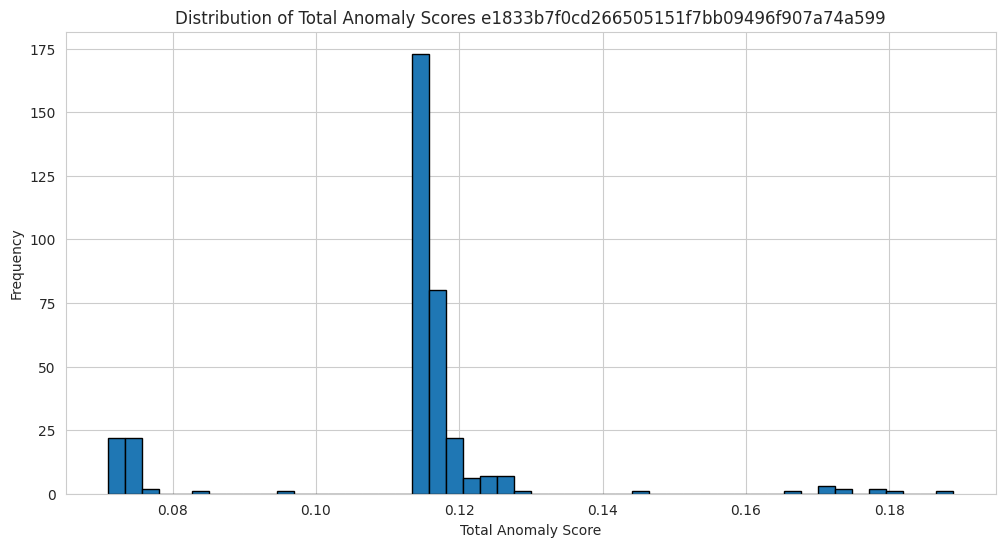

In [9]:
# Distribution of total scores
plt.figure(figsize=(12, 6))
plt.hist(df['weighted_score'], bins=50, edgecolor='black')
plt.xlabel('Total Anomaly Score')
plt.ylabel('Frequency')
plt.title('Distribution of Total Anomaly Scores e1833b7f0cd266505151f7bb09496f907a74a599')
plt.show()

In [10]:
# Top 10 most anomalous commits
top_anomalies = df.nlargest(10, 'weighted_score')[['commit_swhid', 'weighted_score']]
print("Top 10 Most Anomalous Commits:")
print(top_anomalies)

Top 10 Most Anomalous Commits:
                                          commit_swhid  weighted_score
231  swh:1:rev:57f4a963349413b591bddf05dd3edc871425...        0.188971
155  swh:1:rev:2d89378b4f5a7a5de13b1be8aa3eae15b1cb...        0.180419
175  swh:1:rev:a10c42c92a279a96e96174495233f9f15b6c...        0.177940
176  swh:1:rev:dc07565221b77c8db8945d1d680a6fef48b1...        0.177940
248  swh:1:rev:32481f174580745e2687d822c1d778b11651...        0.174229
213  swh:1:rev:b3ef9d7ebfa825a4d7513f46a5e0c8decb46...        0.172694
116  swh:1:rev:cb0819b3fcb9c65b12b9415cc35d335d504a...        0.172050
322  swh:1:rev:c16df72020180bb719a114ca6a5832620ce2...        0.172050
302  swh:1:rev:91d9549de6f9d9b88ac951c5e9288f7ef697...        0.171807
256  swh:1:rev:a816b46f28b0bb22b236dd4e153295b7559b...        0.165410


In [11]:
# Display top 5% of commits by weighted_score in descending order
threshold = df['weighted_score'].quantile(0.95)
top_5_percent = df[df['weighted_score'] >= threshold].sort_values('weighted_score', ascending=False)

print(f"Threshold for top 5%: {threshold}")
print(f"Number of commits in top 5%: {len(top_5_percent)}")
print("\nTop 5% commits by weighted_score:")
top_5_percent[['commit_swhid', 'weighted_score', 'total_score']]

Threshold for top 5%: 0.12555537608126205
Number of commits in top 5%: 19

Top 5% commits by weighted_score:


,commit_swhid,weighted_score,total_score
231,swh:1:rev:57f4a963349413b591bddf05dd3edc871425...,0.188971,0.188971
155,swh:1:rev:2d89378b4f5a7a5de13b1be8aa3eae15b1cb...,0.180419,0.180419
176,swh:1:rev:dc07565221b77c8db8945d1d680a6fef48b1...,0.177940,0.177940
175,swh:1:rev:a10c42c92a279a96e96174495233f9f15b6c...,0.177940,0.177940
248,swh:1:rev:32481f174580745e2687d822c1d778b11651...,0.174229,0.174229
213,swh:1:rev:b3ef9d7ebfa825a4d7513f46a5e0c8decb46...,0.172694,0.172694
116,swh:1:rev:cb0819b3fcb9c65b12b9415cc35d335d504a...,0.172050,0.172050
322,swh:1:rev:c16df72020180bb719a114ca6a5832620ce2...,0.172050,0.172050
302,swh:1:rev:91d9549de6f9d9b88ac951c5e9288f7ef697...,0.171807,0.171807
256,swh:1:rev:a816b46f28b0bb22b236dd4e153295b7559b...,0.165410,0.165410


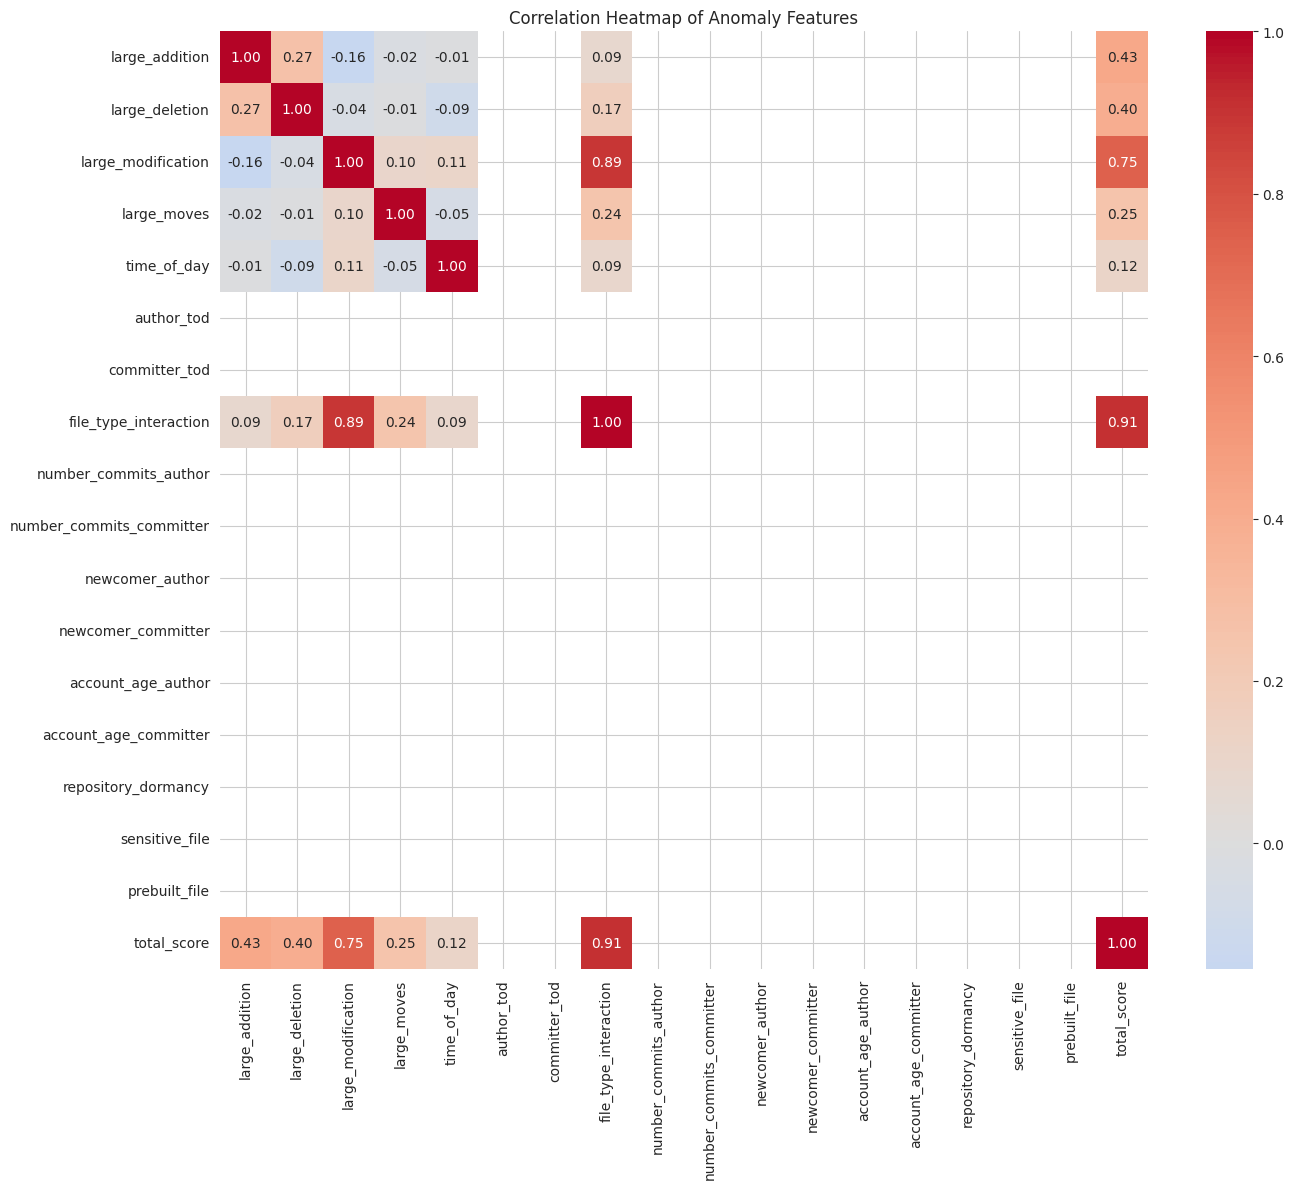

In [ ]:
# Correlation heatmap of anomaly features
anomaly_columns = [
    'large_addition', 'large_deletion', 'large_modification', 'large_moves',
    'time_of_day', 'author_tod', 'committer_tod',
    'file_type_interaction', 'number_commits_author', 'number_commits_committer',
    'newcomer_author', 'newcomer_committer', 'account_age_author', 'account_age_committer',
    'repository_dormancy', 'sensitive_file', 'prebuilt_file', 'total_score'
]

plt.figure(figsize=(14, 12))
correlation_matrix = df[anomaly_columns].corr()
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap of Anomaly Features')
plt.tight_layout()
plt.show()

In [ ]:
# Analyze commits with high specific anomaly indicators
high_addition = df[df['large_addition'] > 0.8]
high_deletion = df[df['large_deletion'] > 0.8]
high_sensitive = df[df['sensitive_file'] > 0.5]

print(f"Commits with large additions: {len(high_addition)}")
print(f"Commits with large deletions: {len(high_deletion)}")
print(f"Commits with sensitive files: {len(high_sensitive)}")

Commits with large additions: 11
Commits with large deletions: 4
Commits with sensitive files: 0


In [ ]:
# Close connection
conn.close()